<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/25_RNN_Gated_Recurrent_Units__GRU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gated Recurrent Units (GRU)

GRU is a **simplified alternative to LSTM** designed to help recurrent neural networks learn long-term dependencies while using a simpler internal structure.

Like LSTM, GRU uses **gates** to control the flow of information through time.

However, GRU simplifies the design:

- **LSTM:** 3 gates + hidden state $H_t$ + separate cell state $C_t$
- **GRU:** 2 gates + a single hidden state $H_t$

The two GRU gates are:

- **Reset gate** → controls how much past information should be ignored when creating new information
- **Update gate** → controls how much of the previous hidden state should be kept

Because GRU has fewer components and parameters, it can be **simpler and faster to train**, while often achieving performance comparable to LSTM.

> **Key idea:** GRU keeps the main idea of gated memory from LSTM, but combines the memory and hidden-state mechanisms into a more compact architecture.

## Reset Gate and Update Gate

GRU simplifies the LSTM by using only **two gates**:

- **Reset gate $R_t$** → controls how much of the previous hidden state should be ignored when creating new candidate information.

Should I use the past to create the NEW candidate?
- **Update gate $Z_t$** → controls how much of the previous hidden state should be carried forward into the new hidden state.

Should I KEEP the past or replace it with the new candidate?



At time step $t$, both gates use:

- the current input $X_t$
- the previous hidden state $H_{t-1}$

The gates are computed as:

$$
R_t = \sigma(X_tW_{xr} + H_{t-1}W_{hr} + b_r)
$$

$$
Z_t = \sigma(X_tW_{xz} + H_{t-1}W_{hz} + b_z)
$$

#

### Why sigmoid?

Both gates use sigmoid, so their values lie between 0 and 1:

- value near **0** → block or reduce information
- value near **1** → allow or preserve information
- values in between → partially allow information



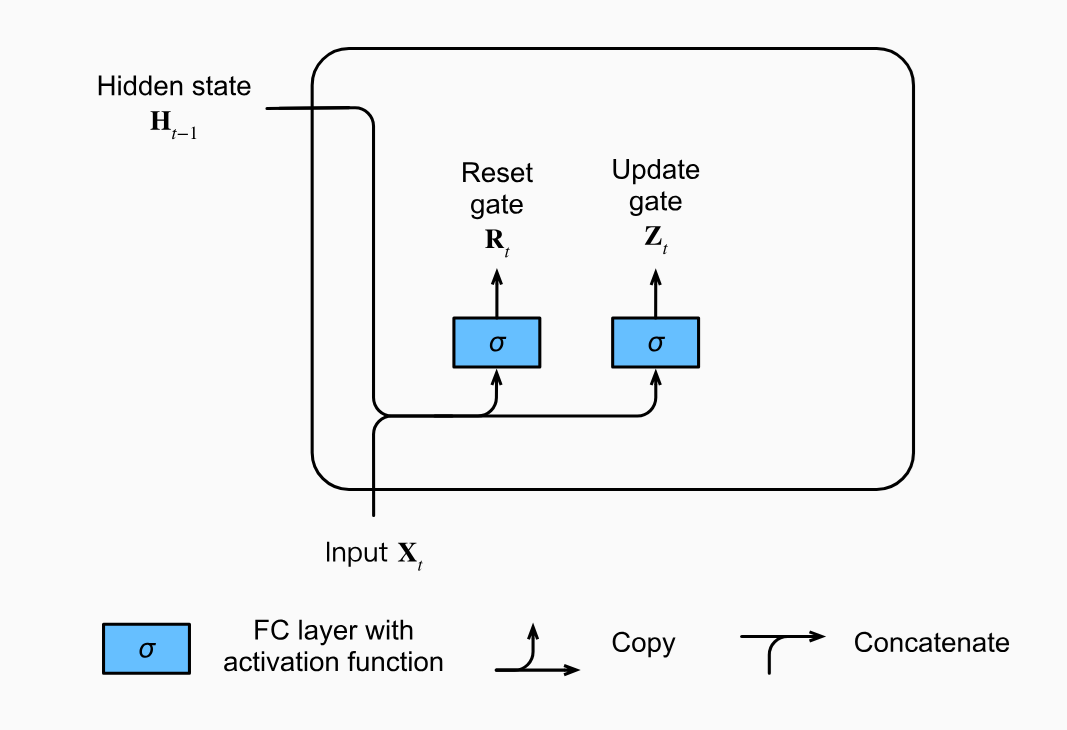

## Candidate Hidden State

After computing the **reset gate $R_t$**, the GRU creates a **candidate hidden state** $\tilde{H}_t$.

The candidate represents:

> **"What could the new hidden state be based on the current input and the relevant parts of the past?"**

It is calculated as:

$$
\tilde{H}_t =
\tanh\left(
X_tW_{xh}
+
(R_t \odot H_{t-1})W_{hh}
+
b_h
\right)
$$

### Role of the Reset Gate

The important part of this equation is:

$$
R_t \odot H_{t-1}
$$

The reset gate determines how much of the **previous hidden state** is considered when creating the candidate.

- $R_t \approx 1$ → use more of the previous hidden state
- $R_t \approx 0$ → ignore more of the previous hidden state

Therefore, the reset gate answers:

> **"How much of the past should I use when creating new information?"**



### Why is it called a candidate?

$\tilde{H}_t$ is called a **candidate** because it is only a proposed new hidden state.

It has not yet become the final hidden state $H_t$.

The GRU will next use the **update gate $Z_t$** to determine how the candidate contributes to the final hidden state.

> **Key idea:** The reset gate controls how much previous information is used to **create the candidate hidden state**.


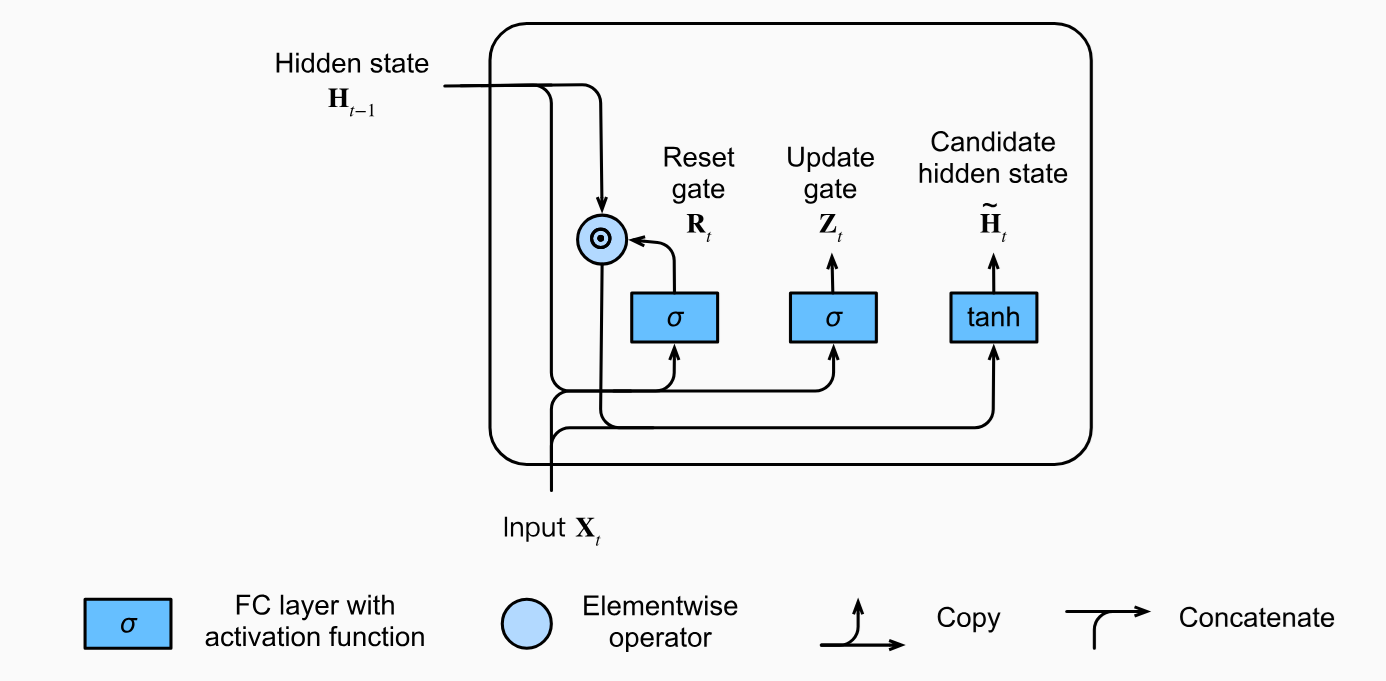

## Hidden State

At this point, the GRU has two possible sources of information:

- **Old hidden state:** $H_{t-1}$
- **Candidate hidden state:** $\tilde{H}_t$

The **update gate $Z_t$** decides how much of each should become the new hidden state $H_t$.

$$
H_t =
Z_t \odot H_{t-1}
+
(1-Z_t) \odot \tilde{H}_t
$$

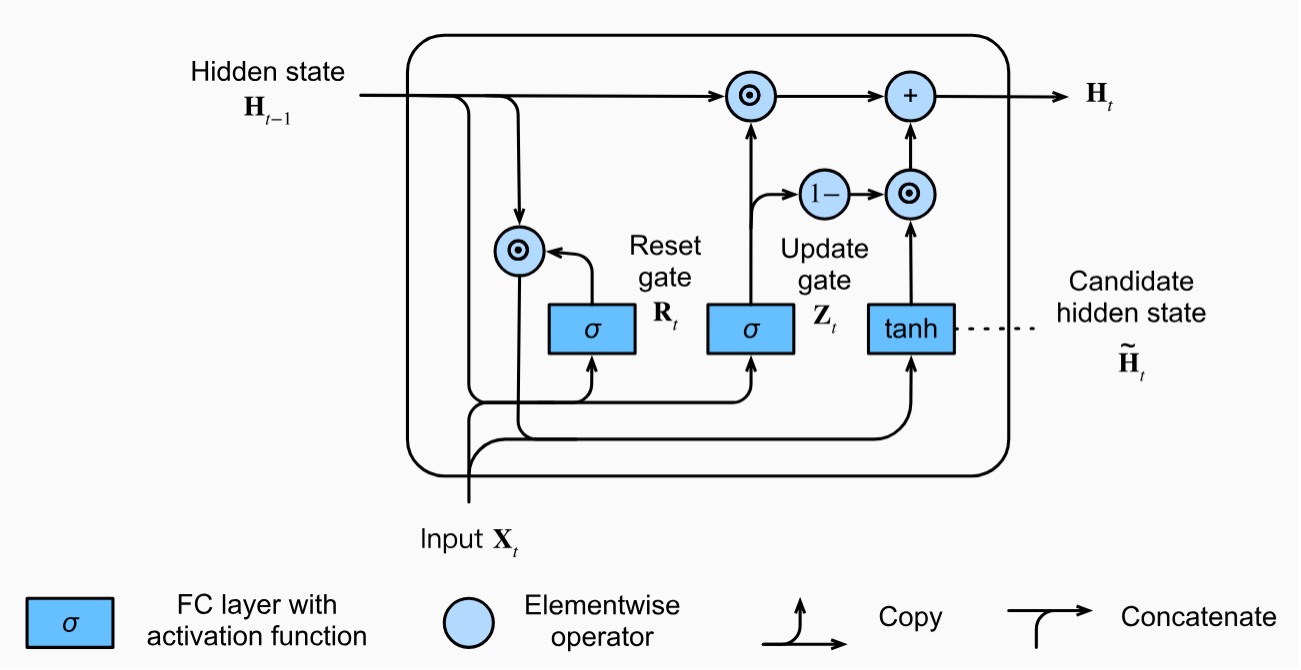

### Understanding the Update Gate

#### If $Z_t \approx 1$

$$
H_t \approx H_{t-1}
$$

The GRU keeps the **old information** and largely ignores the candidate.

> "Keep what I already know."

#### If $Z_t \approx 0$

$$
H_t \approx \tilde{H}_t
$$

The GRU replaces the old information with the **new candidate information**.

> "Use the new information."

#### If $Z_t$ is between 0 and 1

The new hidden state is a **mixture of old and new information**.

### Reset Gate vs. Update Gate

**Reset gate $R_t$**

> "How much of the past should I use when creating the candidate?"

**Update gate $Z_t$**

> "How much of the old state should I keep after creating the candidate?"



### Complete GRU Flow

$$
X_t,\ H_{t-1}
$$

↓ Compute gates

$$
R_t,\ Z_t
$$

↓ Reset gate helps create candidate

$$
\tilde{H}_t
$$

↓ Update gate mixes old state and candidate

$$
\boxed{H_t}
$$

> **Key idea:** The reset gate affects the **creation of new information**, while the update gate determines whether the final hidden state should contain more **old information or new information**.